# 02 · Frequentist Analysis of the Experiment

**Objective:** estimate the effect of each campaign (men's email and women's email) on conversion, visit, and spend, following the analysis plan from notebook 01, and assess how much of what is observed could be due to chance.

**Concepts used**
- **Absolute difference:** the group's rate minus the control's rate, in percentage points (pp). If a rate went from 1% to 1.5%, the absolute difference would be 0.5 pp.
- **Relative increase (lift):** how much the rate grows relative to the control. In the previous example, 50%. It is calculated with the rate ratio: a ratio of 1.5 is equivalent to a relative increase of 50%.
- **95% confidence interval (CI):** range of effect values compatible with the data. If it does not include 0, the difference is statistically significant at 5%. Its width shows how precise the estimate is.
- **P-value:** probability of observing a difference at least this large if the campaign had no effect at all. It does not measure the probability that the campaign works or how large the effect is.
- **Holm correction:** when making several comparisons, the chance of finding "something significant" by chance increases. Holm adjusts the p-values to control that risk, and is less conservative than Bonferroni.
- **Bootstrap:** a method that simulates repeating the experiment by resampling the data with replacement. It is useful for estimating confidence intervals when the distribution is highly skewed, as is the case for spend.

**Comparisons:** men's vs. control, women's vs. control, and men's vs. women's. Within each metric, the Holm correction is applied across the three.

## 1. Setup and data

The libraries, the statistical functions from `src/ab.py`, and the data loading from `src/data.py` are imported. The seed (42) is set so that the bootstrap is reproducible.

In [4]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

from src.data import load_hillstrom, prepare, GRUPOS
from src.ab import (
    compare_proportions, holm_adjust, bootstrap_means, welch_diff,
    n_per_group, mde_two_props,
)

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams["figure.dpi"] = 110

df = prepare(load_hillstrom())
n_group = df["group"].value_counts().reindex(GRUPOS)
print("Customers per group:", n_group.to_dict())

COMPARACIONES = [("men", "control"), ("women", "control"), ("men", "women")]
ETIQUETA = {c: f"{c[0]} − {c[1]}" for c in COMPARACIONES}

Customers per group: {'control': 21306, 'men': 21307, 'women': 21387}


## 2. Global test

Before comparing groups in pairs, a chi-square test across the three groups at once answers whether **any** difference between the groups' rates is compatible with chance. If the global test detected nothing, there would be no point in looking for pairwise differences.

In [5]:
for metric in ["conversion", "visit"]:
    tabla = pd.crosstab(df["group"], df[metric])
    chi2, p, gl, _ = stats.chi2_contingency(tabla)
    print(f"{metric:>10}: chi-square = {chi2:.2f} | gl = {gl} | p = {p:.3g}")

conversion: chi-square = 55.26 | gl = 2 | p = 1e-12
     visit: chi-square = 504.46 | gl = 2 | p = 2.87e-110


## 3. Conversion (primary metric)

For each comparison, the following are reported: the absolute difference with its CI (Newcombe's method, based on Wilson intervals, which works better than the simple formula when the rate is low), the relative increase with its CI (on a logarithmic scale), the p-value from a two-proportion z-test, and the Holm-adjusted p-value.

In [6]:
def tabla_proporciones(metrica):
    x = df.groupby("group", observed=True)[metrica].sum()
    n = df.groupby("group", observed=True)[metrica].size()
    filas = []
    for a, b in COMPARACIONES:
        r = compare_proportions(int(x[a]), int(n[a]), int(x[b]), int(n[b]))
        filas.append({
            "metric": metrica,
            "comparison": ETIQUETA[(a, b)],
            "rate_a_%": 100 * r["p1"],
            "rate_b_%": 100 * r["p0"],
            "dif_pp": 100 * r["diff"],
            "low_ic_pp": 100 * r["low_ic"],
            "high_ic_pp": 100 * r["high_ic"],
            "rel_increase_%": 100 * (r["rr"] - 1),
            "rel_low_%": 100 * (r["rr_low"] - 1),
            "rel_high_%": 100 * (r["rr_high"] - 1),
            "p_value": r["p_value"],
        })
    t = pd.DataFrame(filas)
    t["p_holm"] = holm_adjust(t["p_value"])
    return t

def forest(t, titulo, unit="pp"):
    fig, ax = plt.subplots(figsize=(7, 2.6))
    y = np.arange(len(t))[::-1]
    ax.errorbar(t["dif_pp"], y, xerr=[t["dif_pp"] - t["low_ic_pp"], t["high_ic_pp"] - t["dif_pp"]],
                fmt="o", capsize=4)
    ax.axvline(0, color="red", linestyle="--", linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(t["comparison"])
    ax.set_xlabel(f"Difference ({unit}) with IC 95 %")
    ax.set_title(titulo)
    plt.tight_layout()
    plt.show()

t_conv = tabla_proporciones("conversion")
t_conv.round(5)

,metric,comparison,rate_a_%,rate_b_%,dif_pp,low_ic_pp,high_ic_pp,rel_increase_%,rel_low_%,rel_high_%,p_value,p_holm
0,conversion,men − control,1.25311,0.57261,0.68050,0.50143,0.86407,118.84219,76.79841,170.88424,0.00000,0.00000
1,conversion,women − control,0.88371,0.57261,0.31111,0.15017,0.47455,54.33130,23.01052,93.62694,0.00016,0.00031
2,conversion,men − women,1.25311,0.88371,0.36939,0.17463,0.56626,41.80026,17.81015,70.67555,0.00021,0.00031


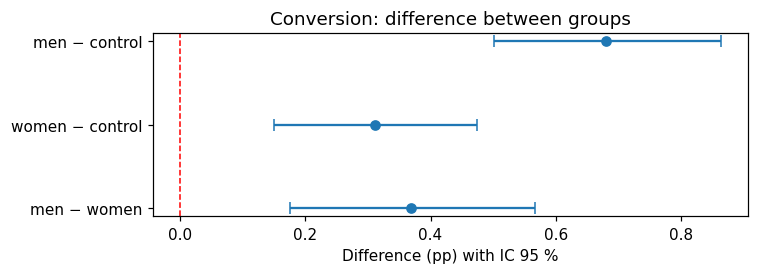

In [7]:
forest(t_conv, "Conversion: difference between groups")

**How to read the table:** `rate_a_%` and `rate_b_%` are the conversion rates of the two groups being compared (the first minus the second); `dif_pp` is the absolute difference in percentage points and `rel_increase_%` is the relative increase, each with its confidence interval. `p_holm` is the p-value adjusted for the three comparisons.

## 4. Site visit (secondary metric)

The same analysis for visits. This metric is more frequent than purchases, so the estimates are more precise, but it is an intermediate step: visiting the site is not the same as generating revenue.

In [8]:
t_visit = tabla_proporciones("visit")
t_visit.round(5)

,metric,comparison,rate_a_%,rate_b_%,dif_pp,low_ic_pp,high_ic_pp,rel_increase_%,rel_low_%,rel_high_%,p_value,p_holm
0,visit,men − control,18.27568,10.61673,7.65896,6.99533,8.32267,72.14046,64.03849,80.64260,0.0,0.0
1,visit,women − control,15.14004,10.61673,4.52331,3.88941,5.15743,42.60551,35.61712,49.95400,0.0,0.0
2,visit,men − women,18.27568,15.14004,3.13565,2.42841,3.84277,20.71095,15.67909,25.96169,0.0,0.0


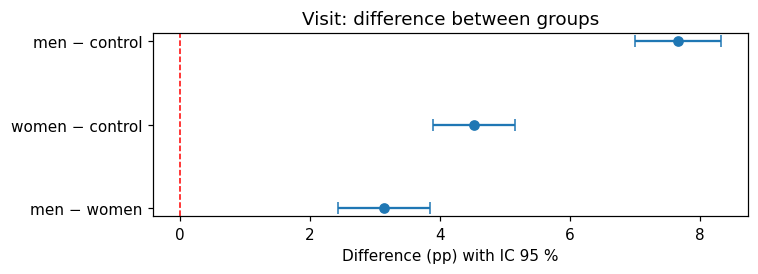

In [9]:
forest(t_visit, "Visit: difference between groups")

## 5. Spend per customer (secondary metric)

Spend per customer includes those who did not purchase (zero spend) and is the measure of the campaign's economic value: the difference in means between a group and the control is the **incremental revenue per customer** who received the email.

Since 99% of customers have zero spend and among those who purchase there is a long tail of high amounts, the distribution is far from normal. For this reason, in addition to Welch's t-test (which compares means without assuming equal variances), a **bootstrap confidence interval** (10,000 resamples) is calculated, which does not depend on normality. The p-value comes from Welch's test, and the intervals from the bootstrap.

In [10]:
N_BOOT = 10_000
gasto = {g: df.loc[df.group == g, "spend"].to_numpy() for g in GRUPOS}
medias_boot = {g: bootstrap_means(gasto[g], N_BOOT, rng) for g in GRUPOS}

filas = []
for a, b in COMPARACIONES:
    w = welch_diff(gasto[a], gasto[b])
    d_boot = medias_boot[a] - medias_boot[b]
    lo, hi = np.percentile(d_boot, [2.5, 97.5])
    filas.append({
        "metric": "spend",
        "comparison": ETIQUETA[(a, b)],
        "mean_a_USD": gasto[a].mean(),
        "mean_b_USD": gasto[b].mean(),
        "dif_USD": w["diff"],
        "ic_boot_low": lo,
        "ic_boot_high": hi,
        "ic_welch_low": w["ic_low"],
        "ic_welch_hig": w["ic_high"],
        "p_value": w["p_value"],
    })
t_gasto = pd.DataFrame(filas)
t_gasto["p_holm"] = holm_adjust(t_gasto["p_value"])
t_gasto.round(4)

,metric,comparison,mean_a_USD,mean_b_USD,dif_USD,ic_boot_low,ic_boot_high,ic_welch_low,ic_welch_hig,p_value,p_holm
0,spend,men − control,1.4226,0.6528,0.7698,0.4822,1.0580,0.4851,1.0545,0.0000,0.0000
1,spend,women − control,1.0772,0.6528,0.4244,0.1747,0.6853,0.1690,0.6799,0.0011,0.0023
2,spend,men − women,1.4226,1.0772,0.3454,0.0348,0.6582,0.0326,0.6583,0.0305,0.0305


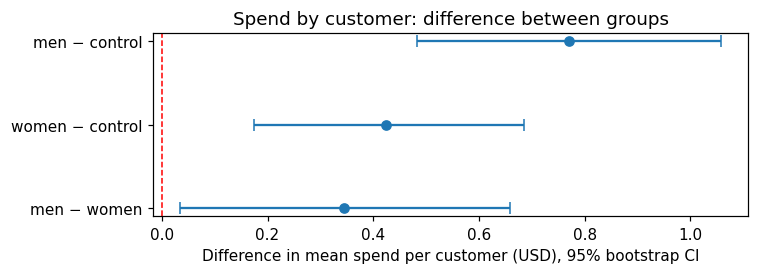

In [11]:
fig, ax = plt.subplots(figsize=(7, 2.6))
y = np.arange(len(t_gasto))[::-1]
ax.errorbar(t_gasto["dif_USD"], y,
            xerr=[t_gasto["dif_USD"] - t_gasto["ic_boot_low"], t_gasto["ic_boot_high"] - t_gasto["dif_USD"]],
            fmt="o", capsize=4)
ax.axvline(0, color="red", linestyle="--", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(t_gasto["comparison"])
ax.set_xlabel("Difference in mean spend per customer (USD), 95% bootstrap CI")
ax.set_title("Spend by customer: difference between groups")
plt.tight_layout()
plt.show()

### 5.1 Incremental revenue per 1,000 emails

Translation into business terms: the difference in mean spend versus the control, multiplied by 1,000 customers. It is **gross revenue**: it does not subtract the cost of the email or the margin on the products (the dataset does not include those data).

In [12]:
incremental = t_gasto[t_gasto["comparison"].str.endswith("control")][
    ["comparison", "dif_USD", "ic_boot_low", "ic_boot_high"]
].copy()
for c in ["dif_USD", "ic_boot_low", "ic_boot_high"]:
    incremental[c] = incremental[c] * 1000
incremental.columns = ["comparison", "incremental_revenue_per_1000_USD", "ic_low", "ic_high"]
incremental.round(1)

,comparison,incremental_revenue_per_1000_USD,ic_low,ic_high
0,men − control,769.8,482.2,1058.0
1,women − control,424.4,174.7,685.3


### 5.2 Sensitivity to high amounts

A few very high amounts can shift the mean. As a check, the difference in means is recalculated by **capping** (winsorizing) spend at the 90th percentile of positive spend. It does not replace the main analysis; it only shows how much of the result depends on the largest purchases.

In [13]:
tope = df.loc[df.spend > 0, "spend"].quantile(0.90)
print(f"Cap applied (90th percentile of positive spend): {tope:.2f} USD")

gasto_lim = {g: np.minimum(gasto[g], tope) for g in GRUPOS}
filas = []
for a, b in COMPARACIONES:
    w = welch_diff(gasto_lim[a], gasto_lim[b])
    filas.append({"comparison": ETIQUETA[(a, b)], "dif_USD_limited": w["diff"],
                  "ic_low": w["ic_low"], "ic_high": w["ic_high"], "p_value": w["p_value"]})
pd.DataFrame(filas).round(4)

Cap applied (90th percentile of positive spend): 256.49 USD


,comparison,dif_USD_limited,ic_low,ic_high,p_value
0,men − control,0.6710,0.4420,0.9000,0.0000
1,women − control,0.3899,0.1786,0.6011,0.0003
2,men − women,0.2811,0.0259,0.5363,0.0309


### 5.3 Spend among those who purchased (descriptive only)

Among those who purchased, mean spend by group is shown for description only. **It cannot be used to compare the campaigns causally**: those who purchase in each group are a subset formed *after* treatment, and it is not comparable across groups even if the original assignment was random.

In [14]:
(df[df.spend > 0].groupby("group", observed=True)["spend"]
   .agg(customers="size", mean_spend="mean", median="median", max="max")
   .round(2))

,customers,mean_spend,median,max
group,,,,
control,122,114.00,88.36,499.0
men,267,113.53,66.98,499.0
women,189,121.89,94.71,499.0


## 6. Summary of results

All effects in a single table, which is also saved to `reports/resultados_frecuentista.csv`. The conversion and visit rows are in percentage points (pp) and the spend rows are in dollars per customer. The `significative_5%_holm` column indicates whether the Holm-adjusted p-value is less than 0.05.

In [15]:
resumen = pd.concat([
    t_conv.assign(unit="pp").rename(columns={"dif_pp": "effect", "low_ic_pp": "low_ic", "high_ic_pp": "high_ic"}),
    t_visit.assign(unit="pp").rename(columns={"dif_pp": "effect", "low_ic_pp": "low_ic", "high_ic_pp": "high_ic"}),
    t_gasto.assign(unit="USD per customer").rename(columns={"dif_USD": "effect", "ic_boot_low": "low_ic", "ic_boot_high": "high_ic"}),
])[["metric", "comparison", "unit", "effect", "low_ic", "high_ic", "rel_increase_%", "p_value", "p_holm"]]
resumen["significative_5%_holm"] = resumen["p_holm"] < 0.05

os.makedirs(os.path.join(ROOT, "reports"), exist_ok=True)
resumen.to_csv(os.path.join(ROOT, "reports", "resultados_frecuentista.csv"), index=False)
resumen.round(5)

,metric,comparison,unit,effect,low_ic,high_ic,rel_increase_%,p_value,p_holm,significative_5%_holm
0,conversion,men − control,pp,0.68050,0.50143,0.86407,118.84219,0.00000,0.00000,True
1,conversion,women − control,pp,0.31111,0.15017,0.47455,54.33130,0.00016,0.00031,True
2,conversion,men − women,pp,0.36939,0.17463,0.56626,41.80026,0.00021,0.00031,True
0,visit,men − control,pp,7.65896,6.99533,8.32267,72.14046,0.00000,0.00000,True
1,visit,women − control,pp,4.52331,3.88941,5.15743,42.60551,0.00000,0.00000,True
2,visit,men − women,pp,3.13565,2.42841,3.84277,20.71095,0.00000,0.00000,True
0,spend,men − control,USD per customer,0.76983,0.48221,1.05798,NaN,0.00000,0.00000,True
1,spend,women − control,USD per customer,0.42441,0.17466,0.68528,NaN,0.00113,0.00226,True
2,spend,men − women,USD per customer,0.34541,0.03484,0.65824,NaN,0.03047,0.03047,True


## 7. Power and sample size

Conversion is a rare event (less than 1% of customers), and detecting small differences in rare events requires large samples. The following are calculated:

- **Minimum detectable effect (MDE):** the smallest difference that the experiment, with the group size it had, would have detected with a probability of 80% (power) and a significance level of 5%.
- **Required sample size** per group to detect different relative increases with respect to the control's conversion rate.

The "observed power" is not calculated from the effect already estimated: it is a direct function of the p-value and provides no new information. What is informative is the MDE and the confidence intervals from the previous sections.

In [16]:
p0 = df.loc[df.group == "control", "conversion"].mean()
n_ctrl = int(n_group["control"])

mde_abs = mde_two_props(p0, n_ctrl)
print(f"Control conversion rate: {100 * p0:.3f} %")
print(f"Customers per group: {n_ctrl:,}")
print(f"MDE at 80% power and alpha = 0.05: {100 * mde_abs:.3f} pp "
      f"(relative increase {100 * mde_abs / p0:.0f} %)")

aumentos = [0.10, 0.20, 0.30, 0.50, 1.00]
necesarios = pd.DataFrame({
    "relative_increase": [f"{int(100 * a)} %" for a in aumentos],
    "ratE_with_campaign_%": [100 * p0 * (1 + a) for a in aumentos],
    "customers_per_group": [n_per_group(p0, p0 * (1 + a)) for a in aumentos],
})
necesarios["vs_real_customers"] = (necesarios["customers_per_group"] / n_ctrl).round(2)
necesarios.round(3)

Control conversion rate: 0.573 %
Customers per group: 21,306
MDE at 80% power and alpha = 0.05: 0.224 pp (relative increase 39 %)


,relative_increase,ratE_with_campaign_%,customers_per_group,vs_real_customers
0,10 %,0.630,286118,13.43
1,20 %,0.687,74911,3.52
2,30 %,0.744,34795,1.63
3,50 %,0.859,13606,0.64
4,100 %,1.145,4073,0.19


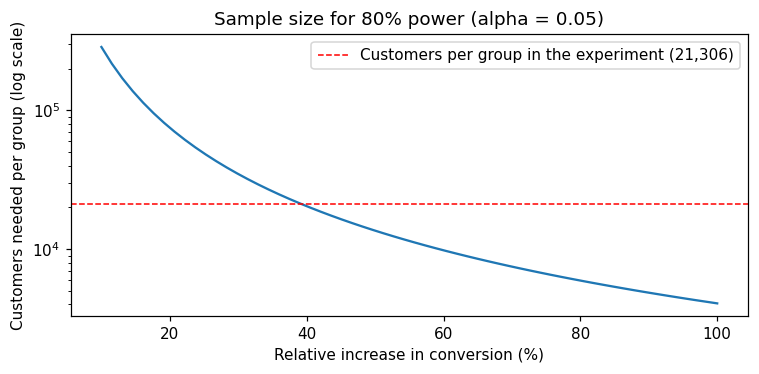

In [17]:
rel = np.linspace(0.10, 1.00, 60)
req = [n_per_group(p0, p0 * (1 + a)) for a in rel]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(100 * rel, req)
ax.axhline(n_ctrl, color="red", linestyle="--", linewidth=1, label=f"Customers per group in the experiment ({n_ctrl:,})")
ax.set_yscale("log")
ax.set_xlabel("Relative increase in conversion (%)")
ax.set_ylabel("Customers needed per group (log scale)")
ax.set_title("Sample size for 80% power (alpha = 0.05)")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Conclusions

- **Global test:** there are differences among the three groups in both conversion (chi-square = 55.3; p = 1e-12) and visits (chi-square = 504.5; p < 1e-100).
- **Conversion (primary metric):** the men's email raises conversion from 0.57% to 1.25% (+0.68 pp; 95% CI: 0.50 to 0.86 pp; relative increase of 119%, CI 77% to 171%). The women's email raises it to 0.88% (+0.31 pp; CI 0.15 to 0.47 pp; +54%, CI 23% to 94%). The men's email outperforms the women's by 0.37 pp (CI 0.17 to 0.57 pp). With the men's email, about 68 additional purchases per 10,000 emails; with the women's, about 31. All Holm-adjusted p-values are below 0.001.
- **Visits (secondary):** 10.6% in control, 15.1% with the women's email, and 18.3% with the men's. The differences versus control are +4.5 pp and +7.7 pp, and between emails, 3.1 pp (all with p < 0.0001). Visiting is an intermediate step: it does not equal revenue.
- **Spend per customer (secondary):** 0.65 dollars in control, 1.08 with the women's email, and 1.42 with the men's. The incremental revenue per customer is 0.77 dollars for men (bootstrap CI 0.48 to 1.06) and 0.42 for women (CI 0.17 to 0.69), that is, 770 and 424 dollars per 1,000 emails. The advantage of the men's email over the women's is 0.35 dollars per customer (CI 0.03 to 0.66; p = 0.03), significant but marginal. The bootstrap and Welch intervals almost coincide, which supports the method despite the skewness of spend.
- **Source of the increase in spend:** spend per customer equals the conversion rate times the mean spend among buyers, and the latter is similar across the three groups (114.00; 113.53 and 121.89 dollars). The higher spend per customer comes mostly from more people buying, not from larger purchases. This comparison among buyers is descriptive only, because that subset is formed after treatment.
- **Sensitivity to high amounts:** when capping spend at the 90th percentile of buyers (256.49 dollars), the effects hold (men − control: +0.67; women − control: +0.39; men − women: +0.28). The result does not depend on a few large purchases. In all three groups the maximum spend is exactly 499 dollars, which suggests a cap in the recording (not verified).
- **Multiple comparisons:** Holm was applied across the three comparisons of each metric. Applying it across all nine comparisons at once, all remain significant at 5%. The p-values that appear as 0.0 in the tables are below 0.00001.
- **Power:** with 21,306 customers per group and a control conversion of 0.57%, the minimum detectable effect (80% power, alpha 0.05) is 0.22 pp, a relative increase of 39%. The observed effects exceed it. In contrast, detecting a 10% relative increase would have required about 286,000 customers per group, 13 times more than were available.
- **Limitations:** revenue is gross, without email costs or product margins; follow-up is only two weeks; the sample is customers who purchased in the last 12 months; and the two emails differ in content (products for men or for women), so the effect of the content cannot be separated from the effect of the audience. The intervals for the relative increase in conversion are wide because this is a rare event.
- **Next step:** notebook 03 complements this analysis with a Bayesian approach (probability that one email outperforms the other) and explores whether the effect changes by customer type.